# Trimestre: serial acquirer scorecard

Run top to bottom (Shift+Enter). Uses two sources:

| Source | Used for | Why |
| --- | --- | --- |
| **Financial statements** (`CSU.TO` etc.) | The score: growth, FCF margin, reinvestment, ROIC, leverage | Same definitions for all 5 companies |
| **Deep profiles** (`csu` etc.) | Named deals, organic growth, each company's own KPIs, filing quotes | Rich and sourced, but every company defines its metrics differently |

**Comparability warning to keep in mind:** Constellation's own "free cash flow" in its profile is FCFA2S (after interest, leases and other claims), which is much lower than standard FCF. Section 9 shows the gap.

## 1. Load

In [1]:
import json, pathlib
import pandas as pd, numpy as np, matplotlib.pyplot as plt
from profiles import load_all, load_statements, statement_scorecard

pd.set_option("display.max_colwidth", 120); pd.set_option("display.width", 220)

TICKERS = {"csu": "CSU.TO", "toi": "TOI.V", "tfii": "TFII.TO", "wsp": "WSP.TO", "aecon": "ARE.TO"}
NAMES = {"csu": "Constellation", "toi": "Topicus", "tfii": "TFI", "wsp": "WSP", "aecon": "Aecon"}

prof = load_all()
st = load_statements(TICKERS)
sc = statement_scorecard(st, years=3)
sc.insert(0, "name", sc.index.map(NAMES))
print("Statement years:", sorted(st["year"].unique()))

Statement years: [np.int64(2021), np.int64(2022), np.int64(2023), np.int64(2024), np.int64(2025)]


## 2. Year by year (statements)

Amounts in each company's reporting currency (USD, EUR, CAD), shown in millions.
**Sanity check:** these come from a standard data provider, not from the quoted filings. Compare a few with the deep-profile figures (section 9) before quoting them on stage.
Known issue: Constellation's operating income (and so NOPAT and ROIC) roughly triples in 2025 in this data, which looks like a definition change, not real performance. Treat its ROIC and incremental ROIC as unverified, or set their weights to 0 in section 4.

In [2]:
yy = st.copy()
for c in ["revenue", "fcf", "acq_spend", "nopat", "invested_capital", "net_debt"]:
    yy[c] = yy[c] / 1e6
yy["name"] = yy["key"].map(NAMES)
yy[["name", "year", "currency", "revenue", "fcf", "acq_spend", "nopat", "invested_capital", "roic", "net_debt"]].round(2)

,name,year,currency,revenue,fcf,acq_spend,nopat,invested_capital,roic,net_debt
0,Constellation,2021,USD,5106.00,1215.24,1053.01,217.00,1676.08,0.13,625.06
1,Constellation,2022,USD,6622.00,1151.67,1374.83,274.62,3220.28,0.09,1491.49
2,Constellation,2023,USD,8407.00,1634.07,1480.62,215.50,5051.41,0.04,3188.90
3,Constellation,2024,USD,10066.00,1888.74,1126.20,439.40,5344.82,0.08,2551.48
4,Constellation,2025,USD,11826.47,2568.18,1072.45,1306.81,6261.58,0.21,2693.09
5,Topicus,2021,EUR,742.54,171.04,209.05,-1619.48,-554.02,NaN,151.58
6,Topicus,2022,EUR,916.68,195.70,129.13,98.45,458.21,0.21,192.11
7,Topicus,2023,EUR,1124.97,238.78,119.18,144.01,447.96,0.32,108.77
8,Topicus,2024,EUR,1294.86,339.34,99.80,178.99,456.96,0.39,145.68
9,Topicus,2025,EUR,1517.94,378.15,242.80,147.86,937.78,0.16,464.77


## 3. Scorecard, last 3 fiscal years

| Measure | Calculation |
| --- | --- |
| revenue_cagr | Revenue growth per year over 3 years |
| fcf_margin | Free cash flow ÷ revenue, 3-year total |
| reinvestment | Acquisition spend ÷ free cash flow, 3-year total (negative = net seller of businesses) |
| roic | After-tax operating income ÷ (equity + net debt), last year |
| incremental_roic | Change in after-tax operating income ÷ change in invested capital over 3 years |
| net_debt_to_ebitda | Leverage, last year |

In [3]:
sc[["name", "currency", "last_fy", "revenue_cagr", "fcf_margin", "reinvestment", "roic",
    "incremental_roic", "net_debt_to_ebitda"]].round(3)

,name,currency,last_fy,revenue_cagr,fcf_margin,reinvestment,roic,incremental_roic,net_debt_to_ebitda
key,,,,,,,,,
aecon,Aecon,CAD,2025,0.050,0.006,-3.049,0.026,NaN,0.590
csu,Constellation,USD,2025,0.213,0.201,0.604,0.209,0.339,1.040
tfii,TFI,USD,2025,0.088,0.076,0.628,0.069,-0.026,2.904
toi,Topicus,EUR,2025,0.183,0.243,0.483,0.158,0.103,1.085
wsp,WSP,CAD,2025,0.153,0.073,0.878,0.092,0.140,1.810


## 4. Score — weights are a starting assumption, change them

Each measure is ranked across the 5 (percentile), then weighted. Leverage counts in reverse.
With 5 companies, look at the raw numbers too: a rank gap can hide a tiny real difference.

In [4]:
WEIGHTS = {                 # measure: (weight, higher_is_better)
    "revenue_cagr":      (0.20, True),
    "fcf_margin":        (0.20, True),
    "reinvestment":      (0.15, True),
    "roic":              (0.20, True),
    "incremental_roic":  (0.15, True),
    "net_debt_to_ebitda": (0.10, False),
}
parts = {c: (sc[c].rank(pct=True, ascending=up) * 100, w) for c, (w, up) in WEIGHTS.items()
         if sc[c].notna().sum() >= 2}
total_w = sum(w for _, w in parts.values())
sc["score"] = sum(r.fillna(r.mean()) * w for r, w in parts.values()) / total_w
sc = sc.sort_values("score", ascending=False)
sc[["name", "score"] + list(parts)].round(3)

,name,score,revenue_cagr,fcf_margin,reinvestment,roic,incremental_roic,net_debt_to_ebitda
key,,,,,,,,
csu,Constellation,88.000,0.213,0.201,0.604,0.209,0.339,1.040
toi,Topicus,71.500,0.183,0.243,0.483,0.158,0.103,1.085
wsp,WSP,62.250,0.153,0.073,0.878,0.092,0.140,1.810
tfii,TFI,45.750,0.088,0.076,0.628,0.069,-0.026,2.904
aecon,Aecon,34.375,0.050,0.006,-3.049,0.026,NaN,0.590


## 5. Valuation: FCF yield — SET ME (exchange rates)

Market caps come from the quotes and are in **CAD** (all 5 trade in Toronto). Free cash flow is in each company's reporting currency, so convert it to CAD first.
Get today's rates from the API (run in the terminal, key set):
`python -c "from onesheet import Onesheet; a=Onesheet(verbose=False); print(a.fx_spot('USDCAD')); print(a.fx_spot('EURCAD'))"`
If that format fails, use any reliable source and note it.

In [5]:
FX_TO_CAD = {"CAD": 1.0, "USD": None, "EUR": None}   # e.g. "USD": 1.38 -- fill in from the API

mcap = {}
for k, tk in TICKERS.items():
    body = json.loads(pathlib.Path(f"data/raw/{tk}/quote.json").read_text(encoding="utf-8"))
    q = body["data"]
    mcap[k] = q.get("marketCap")
    print(f"{tk:8} {q.get('name'):32} price {q.get('price')}  market cap {q.get('marketCap')/1e9:.1f}bn")
sc["market_cap_cad"] = pd.Series(mcap)
sc["fx"] = sc["currency"].map(FX_TO_CAD)
sc["fcf_last_cad"] = sc["fcf_last"] * sc["fx"]
sc["fcf_yield"] = sc["fcf_last_cad"] / sc["market_cap_cad"]
if sc["fx"].isna().any():
    print("\nFill in FX_TO_CAD for:", sorted(sc.loc[sc["fx"].isna(), "currency"].unique()))
sc[["name", "currency", "fcf_last", "fcf_last_cad", "market_cap_cad", "fcf_yield", "score"]].round(3)

CSU.TO   Constellation Software Inc.      price 3496.88  market cap 74.1bn
TOI.V    Topicus.com Inc.                 price 99.37  market cap 8.3bn
TFII.TO  TFI International Inc.           price 137.28  market cap 11.3bn
WSP.TO   WSP Global Inc.                  price 184.33  market cap 24.9bn
ARE.TO   Aecon Group Inc.                 price 55.33  market cap 3.8bn

Fill in FX_TO_CAD for: ['EUR', 'USD']


,name,currency,fcf_last,fcf_last_cad,market_cap_cad,fcf_yield,score
key,,,,,,,
csu,Constellation,USD,2568183966,NaN,74104237426,NaN,88.000
toi,Topicus,EUR,378147670,NaN,8300267022,NaN,71.500
wsp,WSP,CAD,1868400000,1.868400e+09,24850817857,0.075,62.250
tfii,TFI,USD,984484810,NaN,11283454940,NaN,45.750
aecon,Aecon,CAD,60051000,6.005100e+07,3794342282,0.016,34.375


## 6. Charts

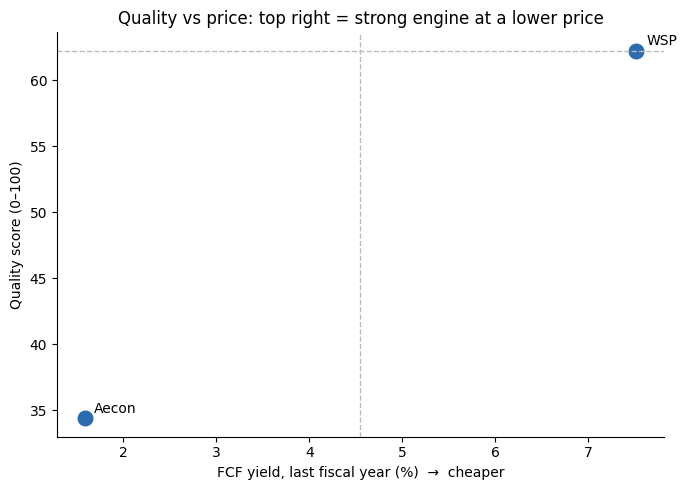

In [6]:
def clean(ax):
    for s in ("top", "right"): ax.spines[s].set_visible(False)

# Quality vs price: the stock-pick chart
d = sc.dropna(subset=["fcf_yield"])
if len(d):
    fig, ax = plt.subplots(figsize=(7, 5))
    ax.scatter(d["fcf_yield"] * 100, d["score"], s=110, color="#2b6cb0")
    for k, r in d.iterrows():
        ax.annotate(r["name"], (r["fcf_yield"] * 100, r["score"]), xytext=(7, 4), textcoords="offset points")
    ax.axhline(sc["score"].median(), color="#bbb", lw=1, ls="--")
    ax.axvline(d["fcf_yield"].median() * 100, color="#bbb", lw=1, ls="--")
    ax.set_xlabel("FCF yield, last fiscal year (%)  →  cheaper"); ax.set_ylabel("Quality score (0–100)")
    ax.set_title("Quality vs price: top right = strong engine at a lower price"); clean(ax)
    plt.tight_layout(); plt.show()
else:
    print("Fill in FX_TO_CAD in section 5 to draw the quality vs price chart.")

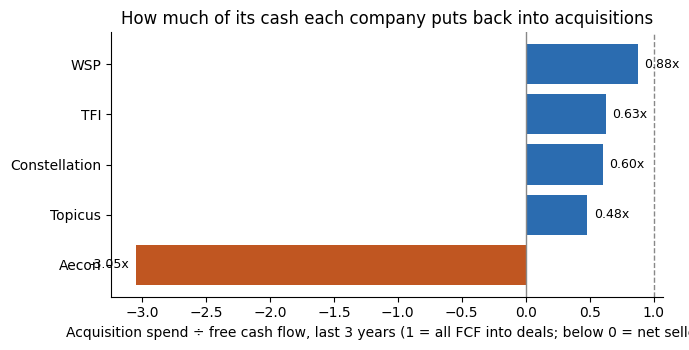

In [7]:
# Where the cash goes: acquisitions vs free cash flow, 3 years
d = sc.sort_values("reinvestment")
fig, ax = plt.subplots(figsize=(7, 3.6))
colors = ["#c05621" if v < 0 else "#2b6cb0" for v in d["reinvestment"]]
ax.barh(d["name"], d["reinvestment"], color=colors)
ax.axvline(0, color="#888", lw=1); ax.axvline(1, color="#888", lw=1, ls="--")
for i, v in enumerate(d["reinvestment"]):
    ax.text(v + (0.05 if v >= 0 else -0.05), i, f"{v:.2f}x", va="center", ha="left" if v >= 0 else "right", fontsize=9)
ax.set_xlabel("Acquisition spend ÷ free cash flow, last 3 years (1 = all FCF into deals; below 0 = net seller)")
ax.set_title("How much of its cash each company puts back into acquisitions"); clean(ax)
plt.tight_layout(); plt.show()

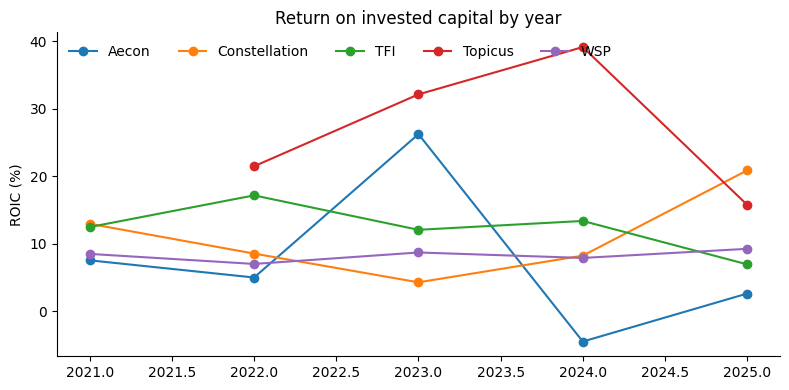

In [8]:
# Is the engine holding up? ROIC by year
piv = st.pivot_table(index="year", columns="key", values="roic").rename(columns=NAMES) * 100
ax = piv.plot(marker="o", figsize=(8, 4))
ax.set_ylabel("ROIC (%)"); ax.set_xlabel(""); ax.set_title("Return on invested capital by year"); clean(ax)
ax.legend(frameon=False, ncol=5, loc="upper left")
plt.tight_layout(); plt.show()

## 7. Deals from the deep profiles (with filing quotes)

**Caution:** `amount_num` is the amount *as written* in each filing. Units vary (millions in one filing, thousands in another), so don't sum or compare amounts across companies without checking the quote.

In [9]:
deals = prof["deals"]
named = deals[~deals["is_aggregate"]].copy()
named["name"] = named["key"].map(NAMES)
print(named.groupby("name").agg(named_deals=("counterparty", "count"), dated=("is_dated", "sum"),
                                with_amount=("amount_num", "count")))
named[["name", "date", "counterparty", "amount_num", "amount_currency", "summary", "quote", "filed_on"]]

               named_deals  dated  with_amount
name                                          
Aecon                    5      5            0
Constellation           10      9            7
TFI                      4      3            5
Topicus                  3      2            2
WSP                     14     12            3


,name,date,counterparty,amount_num,amount_currency,summary,quote,filed_on
28,Aecon,2026-03-09,Ryker Holdings Inc.,NaN,None,"Aecon, through Aecon Utilities Group Inc., completed the acquisition of 100% of Duna Services, LLC and its subsidiar...","On March 9, 2026, the Company, through its subsidiary Aecon Utilities Group Inc., completed the acquisition of 100% ...",2026-04-28
20,Aecon,2025-09-18,Trinity Industrial Services,NaN,None,"Aecon Group Inc. acquired all of the property and assets of Trinity Industrial Services, headquartered in Beaumont, ...","On September 18, 2025, the Company acquired the business of Trinity Industrial Services ('Trinity'), headquartered i...",2025-10-29
24,Aecon,2025-08-07,Bodell Construction Company,NaN,None,"Aecon acquired Bodell Construction Company, an industrial construction company headquartered in Salt Lake City, Utah...","On August 7, 2025, the Company acquired Bodell Construction Company ('Bodell'), an industrial construction company h...",2025-10-29
26,Aecon,2024-12-17,"CriticalPoint Capital, LLC",NaN,None,"Aecon Group Inc. acquired United Engineers & Constructors Inc. from affiliates of CriticalPoint Capital, LLC on Dece...","On December 17, 2024, the Company acquired United Engineers & Constructors Inc. ('United'), a nuclear and convention...",2025-03-05
27,Aecon,2024-07-02,Xtreme Powerline Construction Inc,NaN,None,"Aecon, through its subsidiary Aecon Utilities, acquired Xtreme Powerline Construction Inc., an electrical distributi...","On July 2, 2024, the Company through its subsidiary, Aecon Utilities, acquired a 94.34% interest in Xtreme Powerline...",2025-03-05
12,Constellation,2026-06-01,DerbySoft Holdings Limited,391.0,USD,"Constellation Software acquired 91.8% of DerbySoft Holdings Limited on June 1, 2026 for total consideration of $391.","On June 1, 2026, the Company effectively acquired 91.8% of the outstanding shares of DerbySoft Holdings Limited ('De...",2026-08-11
11,Constellation,2026-02-13,"Synchronoss Technologies, Inc.",309.0,USD,"Constellation Software completed the acquisition of 100% of the shares of Synchronoss Technologies, Inc. for cash pr...","On February 13, 2026, the Company completed the acquisition of 100% of the shares of Synchronoss Technologies, Inc. ...",2026-05-12
10,Constellation,2025-10-01,Asseco,289.0,USD,"Topicus completed the acquisition of 12,318,863 treasury shares of Asseco (14.84% of share capital) on October 1, 20...","The acquisition of the treasury shares closed on October 1, 2025. On October 1, 2025, the restriction was released o...",2025-11-07
13,Constellation,2025-06-02,Cipal Schaubroeck NV,258.0,USD,"Constellation Software Inc. completed the acquisition of 100% of the shares of Cipal Schaubroeck NV, a Belgium-based...","On June 2, 2025, the Company completed the acquisition of the shares of Cipal Schaubroeck NV ('CS'). The Company pai...",2025-08-08
14,Constellation,2025-02-04,Asseco Poland S.A.,NaN,PLN,"Constellation Software entered into a binding agreement on February 4, 2025 to acquire 12,318,863 treasury shares of...","On February 4, 2025, the Company entered into a binding agreement in respect of the acquisition of 12,318,863 treasu...",2025-03-07


In [10]:
# Aggregate lines: many small deals reported as one amount
agg = deals[deals["is_aggregate"]].copy(); agg["name"] = agg["key"].map(NAMES)
agg[["name", "amount_num", "amount_currency", "summary", "quote"]]

,name,amount_num,amount_currency,summary,quote
36,Constellation,673.0,USD,"Constellation Software completed a number of additional acquisitions for aggregate cash consideration of $1,241 plus...",the Company completed or has open commitments to acquire a number of businesses for aggregate cash consideration of ...
37,Constellation,999.0,USD,Constellation Software completed a number of additional acquisitions for aggregate cash consideration of $757 plus h...,the Company completed or has open commitments to acquire a number of businesses for aggregate cash consideration of ...
38,Constellation,320.0,USD,"Subsequent to June 30, 2025, Constellation Software completed or has open commitments to acquire a number of busines...",the Company completed or has open commitments to acquire a number of businesses for aggregate cash consideration of ...
39,Constellation,818.0,USD,"Subsequent to June 30, 2026, Constellation Software completed or has open commitments to acquire multiple businesses...",the Company completed or has open commitments to acquire a number of businesses for aggregate cash consideration of ...
40,Constellation,673.0,USD,"Subsequent to September 30, 2026, Constellation Software completed or has open commitments to acquire multiple busin...",the Company completed or has open commitments to acquire a number of businesses for aggregate cash consideration of ...
43,Topicus,NaN,EUR,"Topicus.com Inc. completed multiple acquisitions during Q1 2026 for total consideration of EUR 22,508 thousand.",acquisitions for an aggregate of €336.6 million (including payments for holdbacks relating to prior acquisitions) of...
44,Topicus,NaN,EUR,Topicus.com Inc. completed multiple acquisitions of software companies across various verticals during the six-month...,"None of the additional acquisitions completed during the year ended December 31, 2025 were deemed to be individually..."
45,Topicus,20284.0,EUR,"Subsequent to December 31, 2025, Topicus.com Inc. entered into agreements to acquire a number of businesses in autom...","Subsequent to December 31, 2025 the Company completed or have entered into agreements to acquire a number of additio..."
46,Topicus,NaN,EUR,"Subsequent to June 30, 2026, Topicus.com Inc. completed or has open commitments to acquire a number of businesses in...","Subsequent to June 30, 2026 the Company completed or has open commitments to acquire a number of businesses for aggr..."
47,Topicus,NaN,EUR,"Subsequent to March 31, 2026, Topicus.com completed or has open commitments to acquire a number of businesses in loc...","Subsequent to March 31, 2026 the Company completed or has open commitments to acquire a number of businesses for agg..."


## 8. Organic growth and company-specific KPIs

What each company reports about its own growth. Not comparable across companies, but strong material for a single-stock pitch.

In [11]:
m = prof["metrics"]
org = m[m["metric_id"].str.contains("organic|acquisition_growth", na=False)].copy()
org["name"] = org["key"].map(NAMES)
org.sort_values(["name", "report_date"])[["name", "report_date", "period_type", "metric_name", "value", "quote"]]

,name,report_date,period_type,metric_name,value,quote
462,Constellation,2026-06-30,Quarterly,Organic growth growth %,0.030,the Company experienced organic growth of 3% and 4% respectively
1637,Topicus,2025-12-31,Quarterly,Organic growth growth %,0.040,the Company experienced organic growth of 4% for both periods
1656,Topicus,2025-12-31,Annual,Organic growth growth %,0.040,the Company experienced organic growth of 4% for both periods
1611,Topicus,2026-03-31,Quarterly,Organic growth growth %,0.050,the Company experienced organic growth of 5% in the quarter
1581,Topicus,2026-06-30,Quarterly,Organic growth growth %,0.040,the Company experienced organic growth of 4% and 5% respectively
1555,Topicus,2026-09-30,Quarterly,Organic growth growth %,0.050,the Company experienced organic growth of 5% for both periods
2707,WSP,2023-12-31,Annual,Net revenue acquisition growth growth %,0.123,to sizeable acquisition growth 12.3%.
2405,WSP,2024-12-31,Quarterly,Organic net revenue growth growth %,0.100,Net revenue organic growth (1) of 10.0% in the quarter was led by the US and Canada.
2437,WSP,2024-12-31,Quarterly,Net revenue acquisition growth growth %,0.101,Acquisition growth* 0.4 % 28.1 % 1.0 % - 10.1 %
2464,WSP,2024-12-31,Annual,Net revenue acquisition growth growth %,0.037,"organic growth of 7.5% led by the US and Canada, as well as acquisition growth of 3.7%"


## 9. Comparability check: company-defined FCF vs standard FCF

Talking point for Q&A: why the score uses statements, not each company's own FCF.

In [12]:
rows = []
for k in TICKERS:
    a = m[(m["key"] == k) & (m["metric_id"] == "free_cash_flow") & (m["period_type"] == "Annual")].sort_values("report_date")
    s = st[(st["key"] == k)].sort_values("year")
    if len(a) and len(s):
        y = a["report_date"].iloc[-1].year
        std = s.loc[s["year"] == y, "fcf"]
        rows.append({"name": NAMES[k], "year": y, "profile_fcf_m": a["value"].iloc[-1] / 1e6,
                     "statement_fcf_m": std.iloc[0] / 1e6 if len(std) else np.nan, "profile_quote": a["quote"].iloc[-1]})
pd.DataFrame(rows).round(0) if rows else "No annual FCF in the profiles to compare"

,name,year,profile_fcf_m,statement_fcf_m,profile_quote
0,Constellation,2025,1683.0,2568.0,"Free cash flow available to shareholders | Year ended - 2025: 1,683"
1,Topicus,2025,219.0,378.0,Free cash flow available to shareholders | : 218.7
2,TFI,2025,832.0,984.0,"Free cash flow | December 31 / 2025: 832,288"
3,WSP,2025,1714.0,1868.0,"Free cash flow (2) $826.7 $642.5 $1,714.1 $884.5"


## 10. Source lookup: the filing quote behind a profile number

`source('wsp', 'backlog')`, `source('csu', 'acquisitions')`

In [13]:
def source(key, metric_id, period_type=None, n=4):
    s = m[(m["key"] == key) & (m["metric_id"] == metric_id)]
    if period_type: s = s[s["period_type"] == period_type]
    return s.sort_values("report_date", ascending=False)[["report_date", "period_type", "value", "currency", "quote", "form", "filed_on"]].head(n)

source("csu", "acquisitions")

,report_date,period_type,value,currency,quote,form,filed_on
432,2026-09-30,Quarterly,-484000000.0,USD,"Acquisition of businesses (note 4) | Three months ended September 30, - 2026: (484)",interim-financial-statements,2026-11-06
460,2026-06-30,Quarterly,-732000000.0,USD,"Acquisition of businesses (note 4) | Three months ended June 30, - 2026: (732)",interim-financial-statements,2026-08-11
490,2026-03-31,Quarterly,-697000000.0,USD,"Acquisition of businesses (note 4) | Three months ended March 31, - 2026: (697)",interim-financial-statements,2026-05-12
516,2025-12-31,Quarterly,-472000000.0,USD,"Acquisition of businesses (note 4) | Year ended December 31, - 2025: (1,227)",annual-financial-statements,2026-03-09


## 11. Export

In [14]:
out = pathlib.Path("output"); out.mkdir(exist_ok=True)
with pd.ExcelWriter(out / "scorecard.xlsx") as xl:
    sc.to_excel(xl, sheet_name="scorecard")
    st.to_excel(xl, sheet_name="statements_by_year", index=False)
    deals.to_excel(xl, sheet_name="deals", index=False)
    m.to_excel(xl, sheet_name="profile_metrics_sources", index=False)
print("Saved", out / "scorecard.xlsx")

Saved output\scorecard.xlsx
